In [1]:
import pandas as pd
import matplotlib.pyplot as plt

shipment = pd.read_csv("../data/Shipment_Details_Cleaned.csv")

print("Shipment dataset loaded successfully!")
print("Total rows and columns:", shipment.shape)

display(shipment.head())

Shipment dataset loaded successfully!
Total rows and columns: (500, 10)


,Shipment_ID,Container_ID,Product,Quantity_KG,Origin_City,Destination_City,Dispatch_Date,Expected_Arrival_Date,Transport_Mode,Transport_Cost
0,SH0001,CONT087,Avocados,11700,Bengaluru,Pune,2025-02-04 18:00:00,2025-02-05 10:05:15,Insulated_Truck,20555.91
1,SH0002,CONT044,Bananas,12300,Bengaluru,Vijayawada,2025-11-20 19:00:00,2025-11-21 14:04:34,Refrigerated_Truck,25200.32
2,SH0003,CONT054,Mangoes,16200,Nagpur,Hyderabad,2025-03-25 08:00:00,2025-03-26 00:10:40,Refrigerated_Truck,14112.03
3,SH0004,CONT030,Tomatoes,5100,Kochi,Vijayawada,2025-08-29 05:00:00,2025-08-30 00:41:52,Refrigerated_Truck,13279.20
4,SH0005,CONT017,Tomatoes,17100,Hyderabad,Tirupati,2025-06-05 15:00:00,2025-06-06 02:21:36,Refrigerated_Truck,24021.68


In [2]:
print("PRODUCT-WISE SHIPMENT COUNT")

product_count = shipment["Product"].value_counts()

display(product_count)

PRODUCT-WISE SHIPMENT COUNT


Product
Bananas     113
Mangoes     109
Grapes       97
Tomatoes     96
Avocados     85
Name: count, dtype: int64

In [3]:
product_summary = shipment.groupby("Product").agg(
    Total_Shipments=("Shipment_ID", "count"),
    Total_Quantity=("Quantity_KG", "sum"),
    Average_Quantity=("Quantity_KG", "mean"),
    Average_Transport_Cost=("Transport_Cost", "mean"),
    Total_Transport_Cost=("Transport_Cost", "sum")
)

print("PRODUCT-WISE SHIPMENT SUMMARY")

display(product_summary.round(2))

PRODUCT-WISE SHIPMENT SUMMARY


,Total_Shipments,Total_Quantity,Average_Quantity,Average_Transport_Cost,Total_Transport_Cost
Product,,,,,
Avocados,85,1014400,11934.12,23018.31,1956556.61
Bananas,113,1278100,11310.62,20779.33,2348064.51
Grapes,97,1077800,11111.34,19576.42,1898913.18
Mangoes,109,1199400,11003.67,21349.06,2327047.63
Tomatoes,96,1147000,11947.92,20746.83,1991695.39


In [4]:
transport_summary = shipment.groupby("Transport_Mode").agg(
    Total_Shipments=("Shipment_ID", "count"),
    Total_Quantity=("Quantity_KG", "sum"),
    Average_Cost=("Transport_Cost", "mean"),
    Total_Cost=("Transport_Cost", "sum")
)

print("TRANSPORT MODE ANALYSIS")

display(transport_summary.round(2))

TRANSPORT MODE ANALYSIS


,Total_Shipments,Total_Quantity,Average_Cost,Total_Cost
Transport_Mode,,,,
Insulated_Truck,118,1327600,20477.36,2416327.93
Rail_Reefer,43,482300,24114.19,1036910.02
Refrigerated_Truck,339,3906800,20852.62,7069039.37


In [5]:
shipment["Dispatch_Date"] = pd.to_datetime(shipment["Dispatch_Date"])
shipment["Expected_Arrival_Date"] = pd.to_datetime(shipment["Expected_Arrival_Date"])

shipment["Expected_Transit_Days"] = (
    shipment["Expected_Arrival_Date"] - shipment["Dispatch_Date"]
).dt.days

print("EXPECTED TRANSIT DURATION")

display(
    shipment.groupby("Product")["Expected_Transit_Days"]
    .mean()
    .round(2)
)

EXPECTED TRANSIT DURATION


Product
Avocados    0.19
Bananas     0.15
Grapes      0.18
Mangoes     0.19
Tomatoes    0.15
Name: Expected_Transit_Days, dtype: float64

In [6]:
print("ORIGIN CITY SHIPMENT COUNT")

display(shipment["Origin_City"].value_counts())

print("DESTINATION CITY SHIPMENT COUNT")

display(shipment["Destination_City"].value_counts())

ORIGIN CITY SHIPMENT COUNT


Origin_City
Bengaluru     66
Nagpur        59
Hyderabad     55
Vijayawada    52
Chennai       50
Pune          43
Mumbai        40
Kochi         35
Ahmedabad     28
Kolkata       28
Tirupati      24
Delhi         20
Name: count, dtype: int64

DESTINATION CITY SHIPMENT COUNT


Destination_City
Hyderabad     64
Bengaluru     61
Vijayawada    51
Mumbai        46
Chennai       44
Nagpur        42
Tirupati      40
Pune          38
Kolkata       33
Ahmedabad     31
Kochi         26
Delhi         24
Name: count, dtype: int64

In [7]:
print("DISPATCH DATES")
display(shipment["Dispatch_Date"].head(10))

print("EXPECTED ARRIVAL DATES")
display(shipment["Expected_Arrival_Date"].head(10))

print("TRANSIT DAYS")
display(shipment["Expected_Transit_Days"].head(10))

print("DATE DIFFERENCE SUMMARY")
display(shipment["Expected_Transit_Days"].describe())

DISPATCH DATES


0   2025-02-04 18:00:00
1   2025-11-20 19:00:00
2   2025-03-25 08:00:00
3   2025-08-29 05:00:00
4   2025-06-05 15:00:00
5   2025-04-02 05:00:00
6   2025-04-03 10:00:00
7   2025-09-26 18:00:00
8   2025-01-21 07:00:00
9   2025-05-12 05:00:00
Name: Dispatch_Date, dtype: datetime64[us]

EXPECTED ARRIVAL DATES


0   2025-02-05 10:05:15
1   2025-11-21 14:04:34
2   2025-03-26 00:10:40
3   2025-08-30 00:41:52
4   2025-06-06 02:21:36
5   2025-04-02 12:47:30
6   2025-04-03 19:09:53
7   2025-09-27 05:06:25
8   2025-01-22 00:02:10
9   2025-05-12 17:38:59
Name: Expected_Arrival_Date, dtype: datetime64[us]

TRANSIT DAYS


0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: Expected_Transit_Days, dtype: int64

DATE DIFFERENCE SUMMARY


count    500.000000
mean       0.170000
std        0.376009
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: Expected_Transit_Days, dtype: float64

In [8]:
shipment["Transit_Hours"] = (
    shipment["Expected_Arrival_Date"] -
    shipment["Dispatch_Date"]
).dt.total_seconds() / 3600

print("TRANSIT DURATION IN HOURS")

display(
    shipment.groupby("Product")["Transit_Hours"]
    .mean()
    .round(2)
)

TRANSIT DURATION IN HOURS


Product
Avocados    18.00
Bananas     17.74
Grapes      17.32
Mangoes     18.03
Tomatoes    16.47
Name: Transit_Hours, dtype: float64

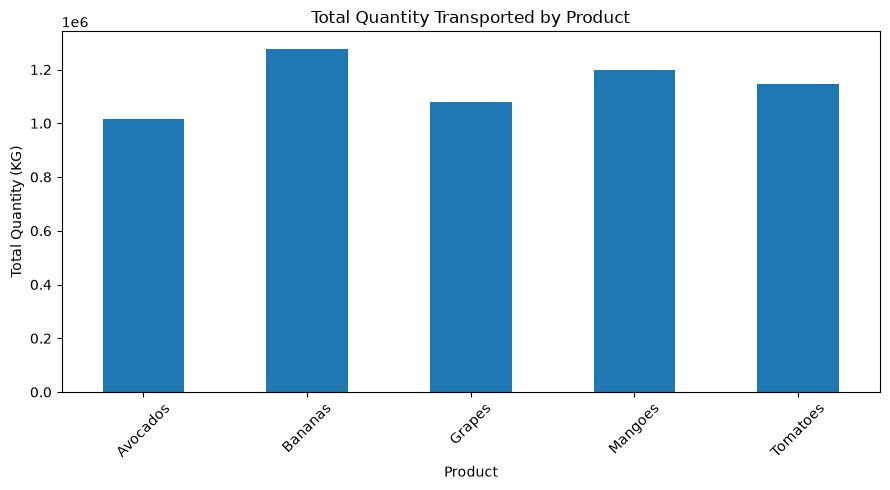

In [9]:
product_summary["Total_Quantity"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Total Quantity Transported by Product")
plt.xlabel("Product")
plt.ylabel("Total Quantity (KG)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
product_summary.to_csv(
    "../outputs/product_shipment_summary.csv"
)

transport_summary.to_csv(
    "../outputs/transport_mode_summary.csv"
)

shipment.to_csv(
    "../outputs/shipment_analysis_data.csv",
    index=False
)

print("Shipment analysis files saved successfully!")

Shipment analysis files saved successfully!
